# 05 · Complaints Simulator — next 60 days

<div dir="rtl">

**الهدف:** نتوقع **نوع** الشكاوى و**عددها** و**مكانها** (المنطقة) لكل يوم من الـ 60 يوم الجايين (1 يناير → 1 مارس 2026)، ومع كل رقم مداه (أحسن حالة وأسوأ حالة) من **Simulator** بيعيد كل يوم 1000 مرة.

**ده مشروع جديد منفصل** عن نوتبوك 04 (توقع الـ 15 يوم)، ومش بيغيّر فيه حاجة.

**الجديد هنا:**
- **الداتا:** بنستخدم **السنة كلها** (يناير–ديسمبر 2025)، مش بعد التطبيق بس، ونعرّف الموديل بإطلاق التطبيق (15 يونيو) عشان مايتلخبطش.
- **المدة:** 60 يوم قدام بدل 15.
- **السيناريوهات:** 4 سيناريوهات:
  1. الطبيعي، مع أحسن وأسوأ حالة
  2. رمضان مفعّل أو لأ
  3. حل مشكلة: تقليل نوع شكوى في منطقة بنسبة
  4. زيادة سكان منطقة

**الوحدة:** منطقة × نوع × يوم = 6 × 15 = **90 سلسلة**.

**الداتا مصطنعة للتدريب:** الأرقام بتثبت إن الطريقة شغالة، مش إن الموديل جاهز لمدينة حقيقية.

</div>

## 1 · Setup and assumptions
<div dir="rtl">

كل الافتراضات مكتوبة هنا في مكان واحد، عشان أي حد يقدر يغيّرها:
- **رمضان 2026:** من 18 فبراير لـ 19 مارس 2026 (تاريخ تقريبي، **افتراض**)
- **أجازات 2026:** 7 يناير و25 يناير، بنفس التاريخ الثابت بتاع 2025 (**افتراض**)
- **الويك إند:** الجمعة والسبت
- **إطلاق التطبيق:** 15 يونيو 2025 (من الداتا)

</div>

In [1]:
from pathlib import Path
import json
import warnings
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd()
DATA = ROOT / "data"                                             # bundled copy
if not (DATA / "req_prepared.parquet").exists():
    DATA = ROOT.parent / "oasis_mob_pss" / "data_clean"          # folder sitting next to oasis_mob_pss
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)
OUT_MODEL = ROOT / "model"; OUT_MODEL.mkdir(exist_ok=True)

WINDOW, HORIZON = 30, 60                    # look back 30 days, forecast 60 days
SEED, N_SIMS = 42, 1000
APP_LAUNCH = pd.Timestamp("2025-06-15")
FIRST_CUTOFF = pd.Timestamp("2025-01-30")              # first day with a full 30-day window
POST_APP_FIRST_CUTOFF = pd.Timestamp("2025-07-30")     # first full window after the launch month
LAST_DAY = pd.Timestamp("2025-12-31")
RAMADAN_2026 = (pd.Timestamp("2026-02-18"), pd.Timestamp("2026-03-19"))            # ASSUMPTION
EXTRA_HOLIDAYS_2026 = [pd.Timestamp("2026-01-07"), pd.Timestamp("2026-01-25")]    # ASSUMPTION
PARAMS = {"objective": "poisson", "learning_rate": 0.03, "num_leaves": 15, "min_data_in_leaf": 40,
          "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 1.0,
          "seed": SEED, "verbose": -1}       # same settings as notebook 04, not tuned on the exams
N_TREES = 400

## 2 · Load all of 2025 and count per zone × type × day
<div dir="rtl">

بنعد الشكاوى لكل منطقة × نوع × يوم على السنة كلها، واليوم اللي مفيهوش شكوى بياخد صفر.

الجدول الشهري بيورّي ليه لازم الموديل يعرف بإطلاق التطبيق: الشكاوى في اليوم اتضاعفت تقريبًا بعد يونيو.

</div>

In [2]:
req = pd.read_parquet(DATA / "req_prepared.parquet",
                      columns=["date", "zone_id", "category_id", "pillar", "is_app", "is_post_app"])
req["date"] = pd.to_datetime(req["date"])
cal = pd.read_parquet(DATA / "calendar.parquet")
cal["date"] = pd.to_datetime(cal["date"])
zones_dim = pd.read_parquet(DATA / "dim_zones.parquet")

print(f"{len(req):,} complaints · rows with missing zone: {int(req['zone_id'].isna().sum())}")
req = req.dropna(subset=["zone_id"])
ZONES = sorted(req["zone_id"].unique())
CATS = sorted(req["category_id"].unique())
NZ, NT = len(ZONES), len(CATS)
PILLAR = req.drop_duplicates("category_id").set_index("category_id")["pillar"]
POP = zones_dim.set_index("zone_id")["population"].reindex(ZONES)

DAYS = pd.date_range("2025-01-01", LAST_DAY, freq="D")
DAY_POS = {d: i for i, d in enumerate(DAYS)}
idx = pd.MultiIndex.from_product([DAYS, ZONES, CATS])
Z = (req.groupby(["date", "zone_id", "category_id"]).size()
     .reindex(idx, fill_value=0).to_numpy().reshape(len(DAYS), NZ, NT))     # day × zone × type
print(f"{NZ} zones × {NT} types = {NZ * NT} series · {len(DAYS)} days · total {Z.sum():,}")

m = req.groupby(req["date"].dt.to_period("M"))
monthly = pd.DataFrame({"complaints": m.size(),
                        "per day": m.size() / pd.Series({p: p.days_in_month for p in m.size().index}),
                        "from app %": 100 * m["is_app"].mean()}).round(1)
monthly

44,817 complaints · rows with missing zone: 0
6 zones × 15 types = 90 series · 365 days · total 44,817


,complaints,per day,from app %
date,,,
2025-01,2310,74.5,0.0
2025-02,2171,77.5,0.0
2025-03,2120,68.4,0.0
2025-04,2462,82.1,0.0
2025-05,2621,84.5,0.0
2025-06,3221,107.4,41.8
2025-07,4771,153.9,61.3
2025-08,4901,158.1,60.3
2025-09,4942,164.7,59.8


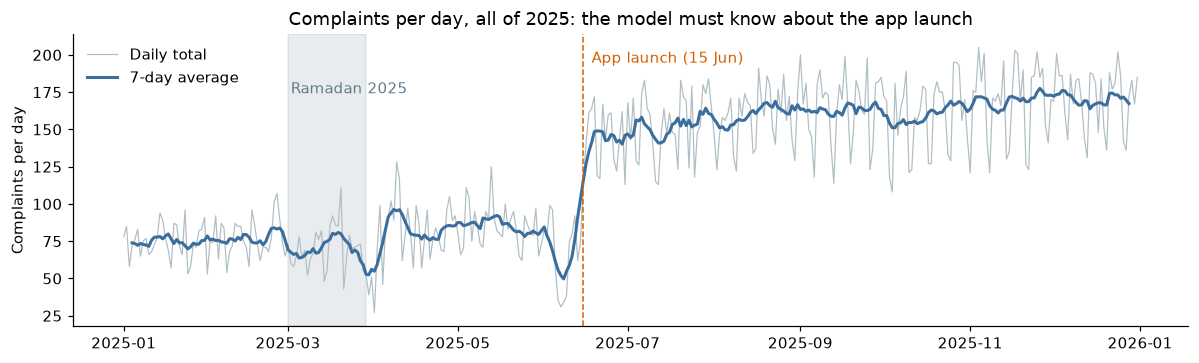

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.4))
tot = pd.Series(Z.sum(axis=(1, 2)), index=DAYS)
ax.plot(tot.index, tot, color="#B0BEC5", lw=0.8, label="Daily total")
ax.plot(tot.index, tot.rolling(7, center=True).mean(), color="#3B6E9C", lw=2, label="7-day average")
ax.axvline(APP_LAUNCH, color="#D55E00", ls="--", lw=1)
ax.text(APP_LAUNCH + pd.Timedelta(days=3), tot.max() * 0.95, "App launch (15 Jun)", color="#D55E00")
ax.axvspan(pd.Timestamp("2025-03-01"), pd.Timestamp("2025-03-29"), color="#90A4AE", alpha=0.2)
ax.text(pd.Timestamp("2025-03-02"), tot.max() * 0.85, "Ramadan 2025", color="#607D8B")
ax.set_title("Complaints per day, all of 2025: the model must know about the app launch")
ax.set_ylabel("Complaints per day"); ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

## 3 · Calendar facts and inputs (features)
<div dir="rtl">

**القاعدة الذهبية:** أي معلومة عن الشكاوى لازم تكون من أيام **قبل يوم التوقف أو فيه**. المعلومات الوحيدة اللي بنعرفها عن المستقبل هي التقويم.

| المعلومة | معناها |
|---|---|
| `zone_id`, `category_id` | المنطقة ونوع الشكوى (كأنواع مش أرقام) |
| `h` | بعد كام يوم من يوم التوقف (1–60) |
| `dow`, `is_weekend`, `is_holiday`, `is_ramadan` | معلومات اليوم المطلوب |
| `post_app` | اليوم المطلوب بعد إطلاق التطبيق؟ |
| `window_post_app_share` | نسبة أيام الـ 30 يوم اللي فاتوا اللي كانت بعد الإطلاق |
| `mean_7`, `mean_30`, `std_30`, `same_dow_4w`, `trend`, `weekend_ratio` | ملخص آخر 30 يوم للمنطقة × النوع |
| `city_mean_30` | متوسط النوع ده في المدينة كلها |
| `zone_share_30` | نسبة المنطقة من النوع ده: (منطقة + 0.5) ÷ (مدينة + 0.5 × 6) |
| `zone_total_mean_30` | متوسط إجمالي شكاوى المنطقة في اليوم |

</div>

In [4]:
HOLIDAYS = set(cal.loc[cal["is_holiday"], "date"]) | set(EXTRA_HOLIDAYS_2026)
RAMADAN = set(cal.loc[cal["is_ramadan"], "date"]) | set(pd.date_range(*RAMADAN_2026))

FEATURES = ["zone_id", "category_id", "h", "dow", "is_weekend", "is_holiday", "is_ramadan", "post_app",
            "window_post_app_share", "mean_7", "mean_30", "std_30", "same_dow_4w", "trend", "weekend_ratio",
            "city_mean_30", "zone_share_30", "zone_total_mean_30"]
H_ = np.arange(1, HORIZON + 1)
ZONE_GRID = np.tile(np.repeat(ZONES, NT), HORIZON)        # row order: h, then zone, then type
TYPE_GRID = np.tile(CATS, NZ * HORIZON)
SAME_K = np.array([[-(-h // 7) + j for j in range(4)] for h in H_])   # 4 latest same weekdays <= cutoff

def make_examples(cutoff, ramadan=True):
    i = DAY_POS[cutoff]
    W = Z[i - WINDOW + 1: i + 1].astype(float)                          # 30 days × zone × type
    wdays = DAYS[i - WINDOW + 1: i + 1]
    wk = wdays.day_of_week.isin([4, 5])
    m7, m30, sd = W[-7:].mean(0), W.mean(0), W.std(0, ddof=1)
    wr = (W[wk].mean(0) + 0.5) / (W[~wk].mean(0) + 0.5)
    city = W.sum(1)                                                     # 30 days × type
    share = (W.sum(0) + 0.5) / (city.sum(0) + 0.5 * NZ)
    ztot = np.repeat(W.sum(2).mean(0), NT).reshape(NZ, NT)
    same = Z[i + H_[:, None] - 7 * SAME_K].mean(1)                       # h × zone × type
    targets = cutoff + pd.to_timedelta(H_, unit="D")
    cal_f = {"dow": targets.day_of_week.to_numpy(),
             "is_weekend": targets.day_of_week.isin([4, 5]).astype(int),
             "is_holiday": np.array([int(d in HOLIDAYS) for d in targets]),
             "is_ramadan": np.array([int(d in RAMADAN) for d in targets]) * int(ramadan),
             "post_app": (targets >= APP_LAUNCH).astype(int)}
    y = np.stack([Z[DAY_POS[d]] if d in DAY_POS else np.full((NZ, NT), np.nan) for d in targets]).astype(float)
    b = lambda a: np.broadcast_to(np.asarray(a, dtype=float), (HORIZON, NZ, NT)).ravel()
    df = pd.DataFrame({
        "cutoff": cutoff, "date": np.repeat(targets, NZ * NT), "h": np.repeat(H_, NZ * NT),
        "zone_id": ZONE_GRID, "category_id": TYPE_GRID,
        **{k: np.repeat(v, NZ * NT) for k, v in cal_f.items()},
        "window_post_app_share": float((wdays >= APP_LAUNCH).mean()),
        "mean_7": b(m7), "mean_30": b(m30), "std_30": b(sd), "same_dow_4w": same.ravel(),
        "trend": b((m7 + 0.5) / (m30 + 0.5)), "weekend_ratio": b(wr),
        "city_mean_30": b(np.broadcast_to(city.mean(0), (NZ, NT))), "zone_share_30": b(share),
        "zone_total_mean_30": b(ztot), "y": y.ravel()})
    df["zone_id"] = pd.Categorical(df["zone_id"], categories=ZONES)
    df["category_id"] = pd.Categorical(df["category_id"], categories=CATS)
    return df

# All training examples once (every cutoff whose 60 target days are inside 2025); each model filters by cutoff.
ALL_CUTOFFS = pd.date_range(FIRST_CUTOFF, LAST_DAY - pd.Timedelta(days=HORIZON), freq="D")
XALL = pd.concat([make_examples(c) for c in ALL_CUTOFFS], ignore_index=True)
num = XALL.select_dtypes("float64").columns
XALL[num] = XALL[num].astype("float32")
print(f"Training examples: {len(ALL_CUTOFFS)} cutoffs ({ALL_CUTOFFS[0]:%d %b}–{ALL_CUTOFFS[-1]:%d %b}) "
      f"× {NZ * NT} series × {HORIZON} days = {len(XALL):,}")
XALL.head(3)

Training examples: 276 cutoffs (30 Jan–01 Nov) × 90 series × 60 days = 1,490,400


,cutoff,date,h,zone_id,category_id,dow,is_weekend,is_holiday,is_ramadan,post_app,...,mean_7,mean_30,std_30,same_dow_4w,trend,weekend_ratio,city_mean_30,zone_share_30,zone_total_mean_30,y
0,2025-01-30,2025-01-31,1,Z01,app,4,1,0,0,0,...,0.000000,0.000000,0.000000,0.0,1.000000,1.000000,0.000000,0.166667,22.9,0.0
1,2025-01-30,2025-01-31,1,Z01,cleanliness,4,1,0,0,0,...,2.142857,1.733333,1.484014,1.5,1.183369,0.726415,7.500000,0.230263,22.9,1.0
2,2025-01-30,2025-01-31,1,Z01,hvac,4,1,0,0,0,...,0.428571,0.433333,0.678911,0.5,0.994898,1.302632,1.966667,0.217742,22.9,1.0


## 4 · Three models
<div dir="rtl">

1. **Baseline:** متوسط نفس اليوم في آخر 4 أسابيع، لكل منطقة × نوع. ونفس النمط الأسبوعي ده بيتكرر على الـ 60 يوم.
2. **LGB-all-year:** موديل LightGBM واحد (Poisson) لكل الـ 90 سلسلة، بيتوقع لحد 60 يوم قدام على طول. ومتدرب على **السنة كلها**، من أول يوم توقف 30 يناير.
3. **LGB-post-app-only:** نفس الموديل بالظبط، بس متدرب على **بعد التطبيق بس** (من 30 يوليو)، عشان نجاوب على سؤال: هل الداتا القديمة بتفيد؟

الموديلين بنفس إعدادات نوتبوك 04، ومش متظبطين على الامتحان.

</div>

In [5]:
def train(first_cutoff, last_cutoff):
    tr = XALL[(XALL["cutoff"] >= first_cutoff) & (XALL["cutoff"] <= last_cutoff)]
    if tr.empty:
        return None, 0
    ds = lgb.Dataset(tr[FEATURES], label=tr["y"], categorical_feature=["zone_id", "category_id"])
    return lgb.train(PARAMS, ds, num_boost_round=N_TREES), tr["cutoff"].nunique()

METHODS = ["Baseline", "LGB-all-year", "LGB-post-app-only"]
FIRSTS = {"LGB-all-year": FIRST_CUTOFF, "LGB-post-app-only": POST_APP_FIRST_CUTOFF}

## 5 · The exam: two 60-day tests
<div dir="rtl">

| الامتحان | يوم التوقف | بيتوقع | آخر يوم توقف في التدريب |
|---|---|---|---|
| Exam A | 31 أغسطس | 1 سبتمبر → 30 أكتوبر | 2 يوليو |
| Exam B | 31 أكتوبر | 1 نوفمبر → 30 ديسمبر | 1 سبتمبر |

الموديل مابيشوفش أي يوم بعد يوم التوقف. و**LGB-post-app-only مينفعش يتمتحن في Exam A**، لأن مفيش ولا يوم توقف بعد التطبيق، الـ 60 يوم بتوعه بيخلصوا قبل 31 أغسطس. ودي نفسها إجابة جزئية على سؤال الداتا القديمة.

</div>

In [6]:
EXAMS = [("Exam A (1 Sep–30 Oct)", pd.Timestamp("2025-08-31")), ("Exam B (1 Nov–30 Dec)", pd.Timestamp("2025-10-31"))]
parts = []
for name, c in EXAMS:
    last = c - pd.Timedelta(days=HORIZON)          # training targets must end on or before the exam cutoff
    test = make_examples(c)
    keep = test[["date", "h", "zone_id", "category_id", "y"]]
    preds = {"Baseline": test["same_dow_4w"].to_numpy()}
    for mname, first in FIRSTS.items():
        model, n = train(first, last)
        if model is None:
            print(f"{name}: {mname} skipped: no training cutoffs between {first:%d %b} and {last:%d %b}")
            continue
        preds[mname] = model.predict(test[FEATURES])
        print(f"{name}: {mname} trained on {n} cutoffs ({first:%d %b}–{last:%d %b})")
    for mname, p in preds.items():
        parts.append(keep.assign(method=mname, exam=name, cutoff=c, pred=p))

bt = pd.concat(parts, ignore_index=True).rename(columns={"y": "actual"})
bt[["zone_id", "category_id"]] = bt[["zone_id", "category_id"]].astype(str)
bt["abs_err"] = (bt["pred"] - bt["actual"]).abs()
bt.to_csv(OUT / "backtest_60d.csv", index=False)
print("Saved:", OUT / "backtest_60d.csv", f"({len(bt):,} rows)")

Exam A (1 Sep–30 Oct): LGB-all-year trained on 154 cutoffs (30 Jan–02 Jul)
Exam A (1 Sep–30 Oct): LGB-post-app-only skipped: no training cutoffs between 30 Jul and 02 Jul


Exam B (1 Nov–30 Dec): LGB-all-year trained on 215 cutoffs (30 Jan–01 Sep)


Exam B (1 Nov–30 Dec): LGB-post-app-only trained on 34 cutoffs (30 Jul–01 Sep)


Saved: C:\Users\NoteBook\Downloads\Capital Project\forecast_60d\outputs\backtest_60d.csv (27,000 rows)


## 6 · Accuracy: daily, weekly, monthly, and for every N = 1..60
<div dir="rtl">

**الدقة = 100% − WAPE**، يعني 100% ناقص (مجموع الأخطاء ÷ مجموع الشكاوى الحقيقية).
- **Daily:** كل يوم لوحده
- **Weekly:** مجموع كل 7 أيام (8 أسابيع كاملة = أول 56 يوم)
- **Monthly:** مجموع كل 30 يوم (شهرين)
- **المستويات:**
  - zone x type: كل نوع في كل منطقة
  - zone total: إجمالي المنطقة
  - city x type: كل نوع في المدينة كلها

</div>

In [7]:
LEVELS = {"zone x type": ["zone_id", "category_id"], "zone total": ["zone_id"], "city x type": ["category_id"]}
VIEWS = {"daily": (lambda h: h, HORIZON), "weekly": (lambda h: (h - 1) // 7, 56), "monthly": (lambda h: (h - 1) // 30, 60)}

def view_scores(df, level, view):
    period, max_h = VIEWS[view]
    d = df[df["h"] <= max_h].assign(period=lambda x: period(x["h"]))
    s = d.groupby(["method", "exam", "period"] + LEVELS[level])[["pred", "actual"]].sum()
    s["err"] = (s["pred"] - s["actual"]).abs()
    g = s.groupby(level="method")
    return pd.DataFrame({"accuracy": 100 * (1 - g["err"].sum() / g["actual"].sum()), "mae": g["err"].mean()})

def score_table(df):
    rows = []
    for view in VIEWS:
        for level in LEVELS:
            rows.append(view_scores(df, level, view).assign(view=view, level=level))
    return pd.concat(rows).reset_index()

both = score_table(bt[bt["method"] != "LGB-post-app-only"]).assign(exams="A+B")
exam_b = score_table(bt[bt["exam"].str.startswith("Exam B")]).assign(exams="B only")
scores = pd.concat([both, exam_b], ignore_index=True)
for ex, d in scores.groupby("exams"):
    print(f"Accuracy %, exams {ex}:")
    display(d.pivot_table(index="method", columns=["view", "level"], values="accuracy").round(1)
            .reindex(columns=list(VIEWS), level=0).reindex(columns=list(LEVELS), level=1))

Accuracy %, exams A+B:


view               daily                             weekly                            monthly                       
level        zone x type zone total city x type zone x type zone total city x type zone x type zone total city x type
method                                                                                                               
Baseline            42.1       84.5        73.2        77.3       92.5        89.4        85.0       94.2        92.0
LGB-all-year        42.6       81.7        72.9        72.4       87.2        83.9        79.2       88.4        86.4

Accuracy %, exams B only:


view                    daily                             weekly                            monthly                       
level             zone x type zone total city x type zone x type zone total city x type zone x type zone total city x type
method                                                                                                                    
Baseline                 43.1       84.4        73.9        77.8       91.6        88.7        84.8       93.2        91.3
LGB-all-year             47.2       85.6        76.3        79.1       93.5        89.3        87.0       95.6        92.6
LGB-post-app-only        47.0       85.5        76.1        78.2       93.3        89.1        86.1       94.9        92.0

### How the model is chosen
<div dir="rtl">

**بنختار على Exam B:**
- ده الامتحان الوحيد اللي الـ 3 موديلات اتمتحنوا فيه.
- وظروفه زي الموديل النهائي بالظبط: وقت التدريب، الموديل كان شاف أيام توقف الـ 30 يوم اللي قبلها كلها بعد التطبيق.
- **المقياس:** متوسط دقة zone x type على daily وweekly وmonthly.

**Exam A بنعرضه بصراحة كتحذير:**
- آخر يوم توقف في تدريبه كان 2 يوليو، يعني الموديل **عمره ما شاف** شهر كامل بعد التطبيق، وبعدين اتطلب منه يتوقع سبتمبر وأكتوبر.
- عشان كده الموديلات المتدربة ممكن تقع فيه تحت الـ Baseline.
- والموديل النهائي مش في الموقف ده، لأنه متدرب لحد 1 نوفمبر.

</div>

In [8]:
zt = lambda ex: scores[(scores["exams"] == ex) & (scores["level"] == "zone x type")].groupby("method")["accuracy"].mean()
ea = score_table(bt[bt["exam"].str.startswith("Exam A")]).query("level == 'zone x type'").groupby("method")["accuracy"].mean()
sb = zt("B only")
CHOSEN = sb.idxmax()
print("Exam B, mean zone × type accuracy over daily/weekly/monthly:", sb.round(2).to_dict())
print("Exam A only (caveat, see above):", ea.round(2).to_dict())
print("Exams A+B:", zt("A+B").round(2).to_dict())
print("Chosen model:", CHOSEN)
OLD_DATA_HELPS = sb.get("LGB-all-year", -1e9) > sb.get("LGB-post-app-only", -1e9)
print("Does the pre-app data help (Exam B, all-year vs post-app-only)?", "yes" if OLD_DATA_HELPS else "no",
      f"({sb.get('LGB-all-year', float('nan')):.2f} vs {sb.get('LGB-post-app-only', float('nan')):.2f})")
if CHOSEN != "Baseline" and ea.get(CHOSEN, 1e9) < ea.get("Baseline", -1e9):
    print(f"CAVEAT: in Exam A the Baseline beat {CHOSEN} ({ea['Baseline']:.2f} vs {ea[CHOSEN]:.2f}).")

Exam B, mean zone × type accuracy over daily/weekly/monthly: {'Baseline': 68.57, 'LGB-all-year': 71.08, 'LGB-post-app-only': 70.45}
Exam A only (caveat, see above): {'Baseline': 67.66, 'LGB-all-year': 58.08}
Exams A+B: {'Baseline': 68.13, 'LGB-all-year': 64.74}
Chosen model: LGB-all-year
Does the pre-app data help (Exam B, all-year vs post-app-only)? yes (71.08 vs 70.45)
CAVEAT: in Exam A the Baseline beat LGB-all-year (67.66 vs 58.08).


In [9]:
def cumulative(df, keys, label, zone="ALL"):
    rows = []
    for n in range(1, HORIZON + 1):
        s = df[df["h"] <= n].groupby(["method", "exam"] + keys)[["pred", "actual"]].sum()
        s["err"] = (s["pred"] - s["actual"]).abs()
        g = s.groupby(level="method")
        rows.append(pd.DataFrame({"days": n, "accuracy": 100 * (1 - g["err"].sum() / g["actual"].sum()),
                                  "mae": g["err"].mean()}))
    return pd.concat(rows).rename_axis("method").reset_index().assign(level=label, zone=zone)

acc_rows = []
for ex_label, d in [("A+B", bt[bt["method"] != "LGB-post-app-only"]), ("B only", bt[bt["exam"].str.startswith("Exam B")])]:
    t = [cumulative(d, LEVELS[l], l) for l in LEVELS]
    t += [cumulative(d[d["zone_id"] == z], ["category_id"], "zone x type", z) for z in ZONES]
    acc_rows.append(pd.concat(t).assign(exams=ex_label, view="first N days (sum)"))
    acc_rows.append(scores[scores["exams"] == ex_label].assign(zone="ALL", days=np.nan))
accuracy = pd.concat(acc_rows, ignore_index=True)[["exams", "method", "view", "level", "zone", "days", "accuracy", "mae"]]
accuracy[["accuracy", "mae"]] = accuracy[["accuracy", "mae"]].round(2)
accuracy.to_csv(OUT / "accuracy_60d.csv", index=False)

show_n = [1, 7, 14, 30, 45, 60]
cum = accuracy[(accuracy["view"] == "first N days (sum)") & (accuracy["zone"] == "ALL") & accuracy["days"].isin(show_n)]
for ex in ["B only", "A+B"]:
    print(f"Accuracy % of the sum over the first N days, exams {ex}:")
    display(cum[cum["exams"] == ex].pivot_table(index=["level", "method"], columns="days", values="accuracy")
            .reindex(list(LEVELS), level=0))
print(f"Per zone, chosen model {CHOSEN} (zone × type):")
pz = accuracy[(accuracy["view"] == "first N days (sum)") & (accuracy["zone"] != "ALL") & (accuracy["method"] == CHOSEN)
              & (accuracy["exams"] == ("A+B" if CHOSEN != "LGB-post-app-only" else "B only")) & accuracy["days"].isin(show_n)]
pz.pivot_table(index="zone", columns="days", values="accuracy")

Accuracy % of the sum over the first N days, exams B only:


days                            1.0    7.0    14.0   30.0   45.0   60.0
level       method                                                     
zone x type Baseline           28.72  79.76  84.33  85.15  85.66  86.06
            LGB-all-year       30.52  80.39  85.07  87.32  88.27  88.38
            LGB-post-app-only  32.02  79.29  84.19  86.15  87.32  87.29
zone total  Baseline           78.31  91.94  94.59  93.44  93.09  93.22
            LGB-all-year       72.71  93.81  96.79  95.49  95.35  95.57
            LGB-post-app-only  73.12  93.86  96.88  95.52  94.99  94.90
city x type Baseline           71.28  87.86  91.59  92.10  93.04  92.18
            LGB-all-year       71.04  88.79  91.00  92.61  94.08  93.37
            LGB-post-app-only  72.59  86.84  90.12  92.18  93.03  92.29

Accuracy % of the sum over the first N days, exams A+B:


days                       1.0    7.0    14.0   30.0   45.0   60.0
level       method                                                
zone x type Baseline      44.24  78.67  83.65  85.40  85.92  86.50
            LGB-all-year  40.53  74.55  78.30  80.23  80.17  80.34
zone total  Baseline      79.91  92.36  94.03  94.83  94.67  94.69
            LGB-all-year  81.23  89.24  89.77  89.48  88.34  88.44
city x type Baseline      70.72  90.04  92.82  92.65  93.11  92.88
            LGB-all-year  73.53  86.53  86.84  87.17  87.26  87.14

Per zone, chosen model LGB-all-year (zone × type):


days,1.0,7.0,14.0,30.0,45.0,60.0
zone,,,,,,
Z01,45.21,77.21,82.22,84.20,84.35,84.42
Z02,58.10,81.63,84.69,83.67,83.13,82.61
Z03,-27.88,47.79,57.12,63.17,67.86,69.87
Z04,9.42,49.07,59.34,64.61,62.41,60.22
Z05,40.31,77.34,79.80,82.66,84.00,85.24
Z06,37.77,74.55,70.87,72.04,69.45,70.40


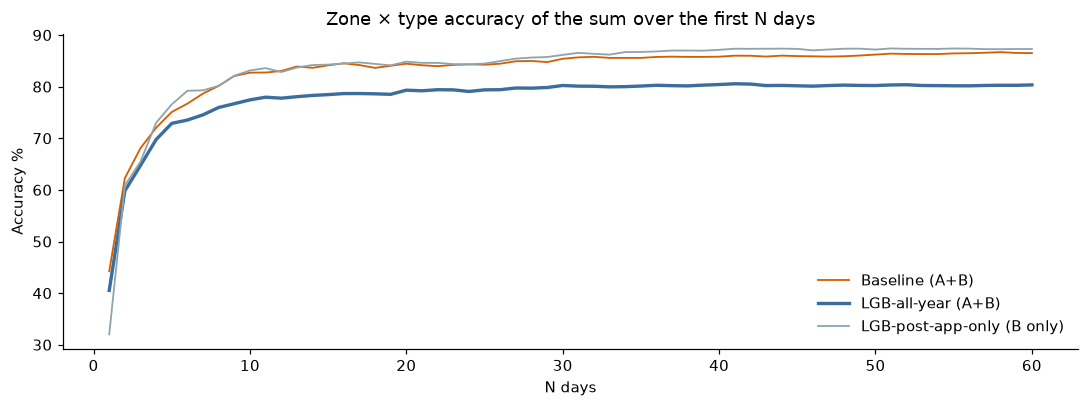

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = {"Baseline": "#D55E00", "LGB-all-year": "#3B6E9C", "LGB-post-app-only": "#90A4AE"}
for mname in METHODS:
    ex = "B only" if mname == "LGB-post-app-only" else "A+B"
    d = accuracy[(accuracy["view"] == "first N days (sum)") & (accuracy["level"] == "zone x type")
                 & (accuracy["zone"] == "ALL") & (accuracy["method"] == mname) & (accuracy["exams"] == ex)]
    ax.plot(d["days"], d["accuracy"], color=colors[mname], lw=2.2 if mname == CHOSEN else 1.2,
            label=f"{mname} ({ex})")
ax.set_title("Zone × type accuracy of the sum over the first N days")
ax.set_xlabel("N days"); ax.set_ylabel("Accuracy %"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 7 · The Simulator: Poisson or negative binomial?
<div dir="rtl">

**الـ Simulator** بياخد المتوقع لكل منطقة × نوع × يوم، ويعيد 1000 مرة بعشوائية واقعية. ومن الـ 1000 بنطلّع:
- **P10:** أحسن حالة (أقل 10%)
- **P50:** النص
- **P90:** أسوأ حالة (أعلى 10%)

**نختار التوزيع من الامتحان نفسه:**
- **Poisson:** لو الأخطاء الحقيقية بحجم العشوائية الطبيعية بس، Poisson كفاية.
- **Negative binomial:** لو الأخطاء أكبر (overdispersion)، بنضيف لكل سلسلة "معامل مستوى" عشوائي، ودي طريقة gamma–Poisson، وبيغطي إن الموديل نفسه ممكن يغلط في مستوى منطقة × نوع على الشهرين.

**الحجم** (σ²) بنقدّره بطريقة **cross-fit**: من Exam A ونجرّب تغطيته على Exam B، والعكس. كده التغطية اللي بنقيسها صادقة.

</div>

In [11]:
ch = bt[bt["method"] == CHOSEN]

def sigma2_from(df):
    # Method of moments on 60-day sums per series: Var(S) = P + sigma2 * P^2.
    s = df.groupby(["zone_id", "category_id"])[["pred", "actual"]].sum()
    return max(0.0, float((((s["actual"] - s["pred"]) ** 2 - s["pred"]).sum()) / (s["pred"] ** 2).sum()))

disp = {ex: float((((d["actual"] - d["pred"]) ** 2) / d["pred"].clip(lower=1e-9)).mean()) for ex, d in ch.groupby("exam")}
sig = {ex: sigma2_from(d) for ex, d in ch.groupby("exam")}
print("Pearson dispersion of daily residuals (1.0 = pure Poisson):", {k: round(v, 3) for k, v in disp.items()})
print("Series-level variance sigma2 per exam:", {k: round(v, 4) for k, v in sig.items()})
OVERDISPERSED = np.mean(list(disp.values())) > 1.1 or max(sig.values()) > 0.005
DIST = "negative binomial (gamma-Poisson, series-level multiplier)" if OVERDISPERSED else "Poisson"
SIGMA2 = float(np.mean(list(sig.values()))) if OVERDISPERSED else 0.0
print("Simulator distribution:", DIST, "· sigma2 used for the final forecast:", round(SIGMA2, 4))

from scipy.stats import poisson

def simulate_draws(mu, sigma2, n=N_SIMS, seed=SEED):
    # mu: series × days. Returns n × series × days counts. Same draw method as simulator_api.simulate.
    rng = np.random.default_rng(seed)
    level = rng.gamma(1 / sigma2, sigma2, size=(n, mu.shape[0], 1)) if sigma2 > 0 else np.ones((n, mu.shape[0], 1))
    u = rng.random((n,) + mu.shape)
    return poisson.ppf(u, np.maximum(mu[None] * level, 1e-12)).astype(np.int32)

def coverage(df, sigma2):
    d = df.sort_values(["zone_id", "category_id", "h"])
    mu = d["pred"].to_numpy().reshape(NZ * NT, HORIZON)
    act = d["actual"].to_numpy().reshape(NZ * NT, HORIZON)
    sims = simulate_draws(mu, sigma2)
    out = {}
    for view, (period, max_h) in VIEWS.items():
        p = period(np.arange(1, max_h + 1))
        k = np.unique(p)
        S = np.stack([sims[:, :, :max_h][:, :, p == j].sum(2) for j in k], -1)
        A = np.stack([act[:, :max_h][:, p == j].sum(1) for j in k], -1)
        lo, hi = np.percentile(S, 10, axis=0), np.percentile(S, 90, axis=0)
        out[view] = 100 * ((A >= lo) & (A <= hi)).mean()
    return out

names = [n for n, _ in EXAMS if n in sig]
cov_rows = []
for target in names:
    other = [n for n in names if n != target]
    s2 = sig[other[0]] if other else sig[target]
    for dist, s in [("Poisson", 0.0), ("Negative binomial", s2)]:
        cov_rows.append({"exam": target, "distribution": dist, "sigma2": round(s, 4),
                         "sigma2 from": other[0] if other else f"{target} (in-sample)",
                         **{f"{v} P10–P90 coverage %": round(c, 1) for v, c in coverage(ch[ch["exam"] == target], s).items()}})
cov = pd.DataFrame(cov_rows)
cov.to_csv(OUT / "simulator_coverage_60d.csv", index=False)
cov

Pearson dispersion of daily residuals (1.0 = pure Poisson): {'Exam A (1 Sep–30 Oct)': 0.977, 'Exam B (1 Nov–30 Dec)': 0.994}
Series-level variance sigma2 per exam: {'Exam A (1 Sep–30 Oct)': 0.0609, 'Exam B (1 Nov–30 Dec)': 0.0105}
Simulator distribution: negative binomial (gamma-Poisson, series-level multiplier) · sigma2 used for the final forecast: 0.0357


,exam,distribution,sigma2,sigma2 from,daily P10–P90 coverage %,weekly P10–P90 coverage %,monthly P10–P90 coverage %
0,Exam A (1 Sep–30 Oct),Poisson,0.0000,Exam B (1 Nov–30 Dec),92.2,65.7,37.8
1,Exam A (1 Sep–30 Oct),Negative binomial,0.0105,Exam B (1 Nov–30 Dec),92.6,68.8,46.1
2,Exam B (1 Nov–30 Dec),Poisson,0.0000,Exam A (1 Sep–30 Oct),92.2,85.4,68.9
3,Exam B (1 Nov–30 Dec),Negative binomial,0.0609,Exam A (1 Sep–30 Oct),93.5,92.6,92.8


<div dir="rtl">

**إزاي تقرا التغطية:** المفروض المدى من P10 لـ P90 يحتوي الرقم الحقيقي في حوالي **80%** من الحالات.
- **اليومي** بيطلع أعلى من 80%، لأن الأعداد صغيرة وصحيحة (0، 1، 2…)، فالمدى من P10 لـ P90 بيشمل أرقام أكتر من النسبة الدقيقة.
- **الأسبوعي والشهري** هما الاختبار الحقيقي: الـ Poisson لوحده بيدّي مدى ضيق جدًا، والـ negative binomial بيصلّحه.
- **التغطية بتختلف من امتحان للتاني**، لأن غلط الموديل في Exam A كان أكبر (شوف خطوة 6). فالمدى تقدير معقول، مش ضمان.

</div>

## 8 · Final model and the 60-day forecast (1 Jan → 1 Mar 2026)
<div dir="rtl">

بندرّب الموديل المختار على كل أيام التوقف اللي الـ 60 يوم بتوعها معروفة (لحد 1 نوفمبر)، وبنتوقع من يوم التوقف 31 ديسمبر. وبعدين الـ Simulator بيعمل 1000 محاولة لكل منطقة × نوع × يوم.

بنحسب كمان نسخة **من غير رمضان**، عشان سيناريو رمضان.

</div>

In [12]:
FORECAST_CUTOFF = LAST_DAY
first = FIRST_CUTOFF if CHOSEN != "LGB-post-app-only" else POST_APP_FIRST_CUTOFF
if CHOSEN == "Baseline":
    final_model = None
    fut = make_examples(FORECAST_CUTOFF)
    mu = mu_off = fut["same_dow_4w"].to_numpy()
else:
    final_model, n_final = train(first, ALL_CUTOFFS[-1])
    print(f"Final {CHOSEN} trained on {n_final} cutoffs ({first:%d %b}–{ALL_CUTOFFS[-1]:%d %b %Y})")
    fut = make_examples(FORECAST_CUTOFF)
    mu = final_model.predict(fut[FEATURES])
    mu_off = final_model.predict(make_examples(FORECAST_CUTOFF, ramadan=False)[FEATURES])

base = fut[["date", "h", "zone_id", "category_id"]].assign(zone_id=lambda d: d["zone_id"].astype(str),
                                                            category_id=lambda d: d["category_id"].astype(str))
base["mean"], base["mean_ramadan_off"] = mu, mu_off
base = base.sort_values(["zone_id", "category_id", "h"], ignore_index=True)
MU = base["mean"].to_numpy().reshape(NZ * NT, HORIZON)
SIMS = simulate_draws(MU, SIGMA2)                                    # 1000 × 90 series × 60 days
pct = np.percentile(SIMS, [10, 50, 90], axis=0)

forecast = pd.DataFrame({
    "zone": base["zone_id"], "date": base["date"].dt.strftime("%Y-%m-%d"), "day_number": base["h"],
    "category_id": base["category_id"], "pillar": base["category_id"].map(PILLAR),
    "mean": base["mean"].round(4), "p10": pct[0].ravel(), "p50": pct[1].ravel(), "p90": pct[2].ravel()})
forecast = forecast.sort_values(["zone", "day_number", "category_id"], ignore_index=True)
forecast.to_csv(OUT / "zone_forecast_60d.csv", index=False)
forecast.to_json(OUT / "zone_forecast_60d.json", orient="records", indent=1, force_ascii=False)
base.assign(date=base["date"].dt.strftime("%Y-%m-%d"))[["zone_id", "date", "h", "category_id", "mean_ramadan_off"]] \
    .rename(columns={"zone_id": "zone", "h": "day_number"}).round(4) \
    .to_csv(OUT / "zone_forecast_60d_ramadan_off.csv", index=False)
print(f"Saved {len(forecast):,} rows ({NZ} zones × {NT} types × {HORIZON} days), "
      f"{base['date'].min():%d %b %Y} → {base['date'].max():%d %b %Y}, distribution: {DIST}")
forecast.head()

Final LGB-all-year trained on 276 cutoffs (30 Jan–01 Nov 2025)


Saved 5,400 rows (6 zones × 15 types × 60 days), 01 Jan 2026 → 01 Mar 2026, distribution: negative binomial (gamma-Poisson, series-level multiplier)


,zone,date,day_number,category_id,pillar,mean,p10,p50,p90
0,Z01,2026-01-01,1,app,citizen_services,1.5171,0.0,1.0,3.0
1,Z01,2026-01-01,1,cleanliness,waste,4.6482,2.0,4.0,8.0
2,Z01,2026-01-01,1,hvac,buildings,1.0333,0.0,1.0,2.0
3,Z01,2026-01-01,1,noise,environment,2.7738,1.0,3.0,5.0
4,Z01,2026-01-01,1,parking,mobility,2.7892,1.0,3.0,5.0


In [13]:
def aggregate(period_of_day, label):
    # Sum the simulated draws per period for every zone × type, then take percentiles.
    p = period_of_day(base["date"].iloc[:HORIZON].reset_index(drop=True))
    rows = []
    keys = base.drop_duplicates(["zone_id", "category_id"])[["zone_id", "category_id"]].to_numpy()
    for j in pd.unique(p):
        m = np.asarray(p == j)
        S = SIMS[:, :, m].sum(2)
        q = np.percentile(S, [10, 50, 90], axis=0)
        dates = base["date"].iloc[:HORIZON][m]
        rows.append(pd.DataFrame({"zone": keys[:, 0], "category_id": keys[:, 1], label: j,
                                  "start_date": dates.min().strftime("%Y-%m-%d"), "end_date": dates.max().strftime("%Y-%m-%d"),
                                  "days": int(m.sum()), "mean": MU[:, m].sum(1).round(2),
                                  "p10": q[0], "p50": q[1], "p90": q[2]}))
    out = pd.concat(rows, ignore_index=True)
    out.insert(2, "pillar", out["category_id"].map(PILLAR))
    return out

weekly = aggregate(lambda d: (d.index // 7) + 1, "week")                 # week 9 = days 57–60
monthly_fc = aggregate(lambda d: d.dt.strftime("%Y-%m"), "month")        # calendar months (Mar = 1 day)
weekly.to_csv(OUT / "zone_forecast_60d_weekly.csv", index=False)
monthly_fc.to_csv(OUT / "zone_forecast_60d_monthly.csv", index=False)

zm = monthly_fc.pivot_table(index="zone", columns="month", values="mean", aggfunc="sum").round(0)
zm["60 days"] = zm.sum(axis=1)
zm.loc["ALL"] = zm.sum()
print("Expected complaints per zone and month (mean):")
display(zm.astype(int))
print("Top types, whole city, Jan and Feb 2026 (mean, with P10–P90 of the city total per type):")
city_sims = {mo: SIMS.reshape(N_SIMS, NZ, NT, HORIZON)[:, :, :, (base["date"].iloc[:HORIZON].dt.strftime("%Y-%m") == mo).to_numpy()].sum((1, 3))
             for mo in ["2026-01", "2026-02"]}
top = []
for mo, S in city_sims.items():
    q = np.percentile(S, [10, 90], axis=0)
    t = pd.DataFrame({"month": mo, "category_id": CATS, "mean": S.mean(0).round(0), "p10": q[0], "p90": q[1]})
    top.append(t.sort_values("mean", ascending=False).head(5))
pd.concat(top, ignore_index=True)

Expected complaints per zone and month (mean):


month,2026-01,2026-02,2026-03,60 days
zone,,,,
Z01,1379,1243,45,2667
Z02,1326,1198,43,2567
Z03,153,133,4,290
Z04,552,504,19,1075
Z05,1400,1263,46,2709
Z06,391,354,13,758
ALL,5201,4695,170,10066


Top types, whole city, Jan and Feb 2026 (mean, with P10–P90 of the city total per type):


,month,category_id,mean,p10,p90
0,2026-01,waste_overflow,552.0,480.9,624.1
1,2026-01,streetlights,527.0,462.0,600.1
2,2026-01,cleanliness,478.0,421.0,540.1
3,2026-01,water_leak,470.0,404.0,538.1
4,2026-01,roads,444.0,382.0,503.0
5,2026-02,waste_overflow,495.0,430.0,561.0
6,2026-02,streetlights,477.0,418.0,539.0
7,2026-02,cleanliness,436.0,380.0,493.0
8,2026-02,water_leak,427.0,365.0,490.0
9,2026-02,roads,402.0,346.0,457.0


## 9 · Save the weights
<div dir="rtl">

- الأوزان بتتحفظ في `model/lightgbm_60d.txt`، وجنبها بطاقة الموديل.
- السكريبت `model/load_and_predict_60d.py` بيعيد بناء عمود `mean` في ملف التوقع من الأوزان، من غير تدريب.
- والـ Simulator نفسه مالوش أوزان: بيستخدم الـ mean والـ σ² اللي في بطاقة الموديل.

</div>

In [14]:
card = {
    "model": CHOSEN, "model_file": "lightgbm_60d.txt" if final_model is not None else None,
    "objective": "poisson", "params": PARAMS, "num_trees": final_model.num_trees() if final_model is not None else 0,
    "features": FEATURES, "categorical_features": ["zone_id", "category_id"],
    "zone_order": ZONES, "category_order": CATS, "pillar": PILLAR[CATS].to_dict(),
    "population": POP.astype(int).to_dict(),
    "window_days": WINDOW, "horizon_days": HORIZON, "share_smoothing": 0.5,
    "training_cutoffs": [str(first.date()), str(ALL_CUTOFFS[-1].date())],
    "forecast_cutoff": str(FORECAST_CUTOFF.date()),
    "forecast_dates": [str(base["date"].min().date()), str(base["date"].max().date())],
    "app_launch": str(APP_LAUNCH.date()), "weekend_dows": [4, 5],
    "holidays": sorted(str(d.date()) for d in HOLIDAYS),
    "ramadan_days": sorted(str(d.date()) for d in RAMADAN),
    "assumptions": {"ramadan_2026": [str(RAMADAN_2026[0].date()), str(RAMADAN_2026[1].date())],
                    "extra_holidays_2026": [str(d.date()) for d in EXTRA_HOLIDAYS_2026]},
    "simulator": {"distribution": DIST, "sigma2": SIGMA2, "n_sims": N_SIMS, "seed": SEED},
    "versions": {p: version(p) for p in ["lightgbm", "pandas", "numpy", "scipy", "pyarrow"]},
}
if final_model is not None:
    final_model.save_model(str(OUT_MODEL / "lightgbm_60d.txt"))
    reloaded = lgb.Booster(model_file=str(OUT_MODEL / "lightgbm_60d.txt"))
    print("Reloaded model gives identical predictions:", np.allclose(reloaded.predict(fut[FEATURES]), mu))
(OUT_MODEL / "model_card_60d.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
print("Saved:", OUT_MODEL / "model_card_60d.json")

Reloaded model gives identical predictions: True
Saved: C:\Users\NoteBook\Downloads\Capital Project\forecast_60d\model\model_card_60d.json


## 10 · Scenarios with `simulate(...)`
<div dir="rtl">

الدالة موجودة في `simulator_api.py`، وبتقرا ملفات التوقع وبطاقة الموديل بس، فمش محتاجة الموديل ولا LightGBM.

- **المدخلات:**
  - `zone`: ‏`"ALL"` أو `"Z01"`…`"Z06"`
  - `days`: من 1 لـ 60
  - `view`: ‏`"daily"` أو `"weekly"` أو `"monthly"`
  - `scenario`: واحد من 4
- **السيناريوهات الـ 4:**

| السيناريو | معناه | جاي منين |
|---|---|---|
| `normal` | الطبيعي، مع P10 (أحسن حالة) وP90 (أسوأ حالة) | الموديل + الـ Simulator |
| `ramadan_off` | لو مفيش رمضان، والفرق = أثر رمضان | الموديل اتعلم رمضان من 2025 |
| `fix` | تقليل نوع شكوى في منطقة بنسبة من يوم معين | **افتراض من المستخدم** (النسبة) |
| `population` | سكان منطقة يتغيّروا، بنفس معدل الشكاوى لكل 1000 ساكن | السكان من `dim_zones` + **افتراض** إن المعدل لكل ساكن ثابت |

- **الطبيعي والسيناريو بيتحسبوا بنفس الأرقام العشوائية**، فالفرق بينهم بيبيّن أثر السيناريو بس.

</div>

In [15]:
import importlib
import simulator_api
importlib.reload(simulator_api)            # read the files this run just wrote
from simulator_api import simulate

def show(r, n=8):
    print(f"Scenario {r['scenario']} · zone {r['zone']} · {r['days']} days ({r['dates'][0]} → {r['dates'][1]}) · view {r['view']}")
    for a in r["assumptions"]:
        print("  •", a)
    t = r["total"]
    print(f"  Total: normal {t['normal_mean']:.0f} [{t['normal_p10']:.0f}–{t['normal_p90']:.0f}] → "
          f"scenario {t['mean']:.0f} [{t['p10']:.0f}–{t['p90']:.0f}] ({t['change']:+.0f}, {t['change_pct']:+.1f}%)")
    if n:
        display(r["by_type"].head(n))

# 1) Normal, all zones, 60 days, monthly view
r = simulate("ALL", days=60, view="monthly", scenario="normal")
show(r)
display(r["by_zone"])
r["by_period"]

Scenario normal · zone ALL · 60 days (2026-01-01 → 2026-03-01) · view monthly
  • Simulator: negative binomial (gamma-Poisson, series-level multiplier), sigma2 = 0.0357, 1000 draws, seed 42.
  Total: normal 10066 [9720–10407] → scenario 10066 [9720–10407] (+0, +0.0%)


,category_id,pillar,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,waste_overflow,waste,1069.77,929.9,1204.0,1069.77,929.9,1204.0,0.0,0.0
1,streetlights,public_safety,1016.61,899.0,1149.1,1016.61,899.0,1149.1,0.0,0.0
2,cleanliness,waste,928.10,821.0,1043.1,928.10,821.0,1043.1,0.0,0.0
3,water_leak,water,917.73,788.9,1041.1,917.73,788.9,1041.1,0.0,0.0
4,roads,mobility,859.82,745.0,972.0,859.82,745.0,972.0,0.0,0.0
5,parking,mobility,806.40,705.0,905.0,806.40,705.0,905.0,0.0,0.0
6,noise,environment,688.79,601.0,776.0,688.79,601.0,776.0,0.0,0.0
7,water_outage,water,639.45,549.0,730.0,639.45,549.0,730.0,0.0,0.0


,zone,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,Z05,2708.81,2530.9,2915.1,2708.81,2530.9,2915.1,0.0,0.0
1,Z01,2666.92,2472.8,2841.0,2666.92,2472.8,2841.0,0.0,0.0
2,Z02,2567.53,2389.9,2764.1,2567.53,2389.9,2764.1,0.0,0.0
3,Z04,1074.64,989.0,1156.1,1074.64,989.0,1156.1,0.0,0.0
4,Z06,757.47,691.0,828.1,757.47,691.0,828.1,0.0,0.0
5,Z03,290.51,260.0,321.0,290.51,260.0,321.0,0.0,0.0


,period,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,2026-01,5202.08,5009.8,5396.0,5202.08,5009.8,5396.0,0.0,0.0
1,2026-02,4694.97,4518.9,4864.1,4694.97,4518.9,4864.1,0.0,0.0
2,2026-03,168.84,152.0,186.0,168.84,152.0,186.0,0.0,0.0


In [16]:
# 2) Ramadan effect: normal (with Ramadan from 18 Feb) vs Ramadan off, all zones, 60 days
r_ram = simulate("ALL", days=60, view="weekly", scenario="ramadan_off")
show(r_ram, n=15)
r_ram["by_period"]

Scenario ramadan_off · zone ALL · 60 days (2026-01-01 → 2026-03-01) · view weekly
  • Simulator: negative binomial (gamma-Poisson, series-level multiplier), sigma2 = 0.0357, 1000 draws, seed 42.
  • Normal includes Ramadan 2026-02-18 → 2026-03-19 (ASSUMED dates); scenario switches Ramadan off. The effect is learned from Ramadan 2025 (before the app launch).
  Total: normal 10066 [9720–10407] → scenario 10263 [9909–10610] (+198, +2.0%)


,category_id,pillar,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,waste_overflow,waste,1069.77,929.9,1204.0,1096.03,953.0,1234.0,26.27,2.46
1,streetlights,public_safety,1016.61,899.0,1149.1,1037.73,915.0,1174.2,21.11,2.08
2,cleanliness,waste,928.10,821.0,1043.1,946.12,836.0,1061.1,18.02,1.94
3,water_leak,water,917.73,788.9,1041.1,932.67,802.0,1058.1,14.94,1.63
4,roads,mobility,859.82,745.0,972.0,872.30,756.9,986.1,12.48,1.45
5,parking,mobility,806.40,705.0,905.0,828.47,724.0,929.0,22.07,2.74
6,noise,environment,688.79,601.0,776.0,696.97,608.0,783.1,8.18,1.19
7,water_outage,water,639.45,549.0,730.0,646.07,555.0,737.1,6.62,1.03
8,safety,public_safety,564.41,494.0,636.0,574.36,502.0,647.1,9.95,1.76
9,sewer,water,555.90,480.0,636.0,573.21,494.9,656.1,17.31,3.11


,period,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,week 1,1175.73,1120.0,1232.0,1175.73,1120.0,1232.0,0.00,0.00
1,week 2,1206.45,1149.9,1266.0,1206.45,1149.9,1266.0,0.00,0.00
2,week 3,1207.11,1148.0,1263.1,1207.11,1148.0,1263.1,0.00,0.00
3,week 4,1143.52,1088.0,1199.1,1143.52,1088.0,1199.1,0.00,0.00
4,week 5,1216.60,1158.0,1277.0,1216.60,1158.0,1277.0,0.00,0.00
5,week 6,1218.91,1163.0,1275.1,1218.91,1163.0,1275.1,0.00,0.00
6,week 7,1201.54,1141.0,1265.0,1218.94,1156.0,1281.1,17.41,1.45
7,week 8,1102.72,1049.0,1158.0,1218.94,1158.0,1279.1,116.22,10.54
8,week 9,593.30,558.0,631.0,657.21,620.0,698.0,63.91,10.77


In [17]:
# 3) Fix a problem: Z01 streetlights −30% from 15 Jan 2026 (user assumption)
r_fix = simulate("Z01", days=60, view="monthly", scenario="fix", category="streetlights",
                 start_date="2026-01-15", reduce_pct=30)
show(r_fix, n=0)
display(r_fix["by_type"][r_fix["by_type"]["category_id"] == "streetlights"])
r_fix["by_period"]

Scenario fix · zone Z01 · 60 days (2026-01-01 → 2026-03-01) · view monthly
  • Simulator: negative binomial (gamma-Poisson, series-level multiplier), sigma2 = 0.0357, 1000 draws, seed 42.
  • USER ASSUMPTION: streetlights complaints in Z01 drop 30% from 2026-01-15 on.
  Total: normal 2667 [2485–2860] → scenario 2603 [2427–2791] (-64, -2.4%)


,category_id,pillar,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
5,streetlights,public_safety,277.66,214.0,348.1,214.12,164.0,269.0,-63.54,-22.89


,period,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,2026-01,1378.95,1278.9,1487.0,1355.63,1256.0,1462.0,-23.32,-1.69
1,2026-02,1243.39,1152.0,1341.1,1204.55,1117.9,1298.0,-38.83,-3.12
2,2026-03,44.58,36.0,54.0,43.19,34.0,53.0,-1.39,-3.13


In [18]:
# 4) Population growth: Z04 from 6,000 to 9,000 residents (same complaints per 1,000 residents)
r_pop = simulate("Z04", days=60, view="monthly", scenario="population", new_population=9000)
show(r_pop, n=5)
r_pop["by_period"]

Scenario population · zone Z04 · 60 days (2026-01-01 → 2026-03-01) · view monthly
  • Simulator: negative binomial (gamma-Poisson, series-level multiplier), sigma2 = 0.0357, 1000 draws, seed 42.
  • ASSUMPTION: Z04 population 6,000 → 9,000 (×1.50) with the same complaints per 1,000 residents for every type.
  Total: normal 1075 [993–1160] → scenario 1612 [1495–1735] (+537, +50.0%)


,category_id,pillar,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,parking,mobility,137.39,101.0,176.0,206.09,151.0,262.1,68.70,50.0
1,cleanliness,waste,121.72,90.0,156.0,182.58,138.0,232.0,60.86,50.0
2,waste_overflow,waste,120.65,91.0,153.0,180.97,137.0,229.0,60.32,50.0
3,roads,mobility,98.73,73.0,131.0,148.09,110.0,194.1,49.36,50.0
4,streetlights,public_safety,90.52,68.0,117.0,135.79,103.0,173.0,45.26,50.0


,period,normal_mean,normal_p10,normal_p90,mean,p10,p90,change,change_pct
0,2026-01,552.46,504.0,600.0,828.69,761.0,897.0,276.23,50.0
1,2026-02,503.67,460.0,549.0,755.51,695.0,820.1,251.84,50.0
2,2026-03,18.50,13.0,24.0,27.76,21.0,35.0,9.25,50.0


In [19]:
def scen_rows(r, name):
    t = r["by_type"].assign(example=name, zone=r["zone"], days=r["days"])
    return t

examples = pd.concat([scen_rows(r_ram, "Ramadan off vs normal (ALL, 60 days)"),
                      scen_rows(r_fix, "Fix: Z01 streetlights -30% from 2026-01-15"),
                      scen_rows(r_pop, "Population: Z04 6,000 -> 9,000")], ignore_index=True)
examples.to_csv(OUT / "scenario_examples_60d.csv", index=False)
print("Saved:", OUT / "scenario_examples_60d.csv", f"({len(examples)} rows)")
# Validation of inputs
for bad in [dict(zone="Z09"), dict(days=0), dict(days=61), dict(view="yearly"), dict(scenario="crisis"),
            dict(zone="Z01", scenario="fix", category="water", start_date="2026-01-15", reduce_pct=30),
            dict(zone="Z01", scenario="fix", category="streetlights", start_date="2026-01-15", reduce_pct=150)]:
    try:
        simulate(**bad); print("NO ERROR for", bad)
    except ValueError as e:
        print("Rejected:", e)

Saved: C:\Users\NoteBook\Downloads\Capital Project\forecast_60d\outputs\scenario_examples_60d.csv (45 rows)
Rejected: zone must be 'ALL' or one of ['Z01', 'Z02', 'Z03', 'Z04', 'Z05', 'Z06'], got 'Z09'
Rejected: days must be a whole number from 1 to 60, got 0
Rejected: days must be a whole number from 1 to 60, got 61
Rejected: view must be one of ('daily', 'weekly', 'monthly'), got 'yearly'
Rejected: scenario must be one of ('normal', 'ramadan_off', 'fix', 'population'), got 'crisis'
Rejected: category must be one of ['app', 'cleanliness', 'hvac', 'noise', 'parking', 'parks', 'power_outage', 'roads', 'safety', 'sewer', 'streetlights', 'traffic_signals', 'waste_overflow', 'water_leak', 'water_outage'], got 'water'
Rejected: reduce_pct must be a number from 0 to 100, got 150


## 11 · Summary
<div dir="rtl">

- **بنتوقع:** لكل منطقة (6) × نوع (15) × يوم (60): العدد المتوقع، ومعاه أحسن حالة (P10) وأسوأ حالة (P90) من 1000 محاولة.
- **اتدربنا:** على السنة كلها، والموديل عارف إطلاق التطبيق ورمضان والأجازات. واتمتحنا على 60 يوم مرتين (سبتمبر–أكتوبر، ونوفمبر–ديسمبر). والموديل المختار والأرقام في الخطوات 6 و7.
- **السيناريوهات:** الطبيعي، ورمضان، وحل مشكلة، وزيادة سكان، بدالة `simulate(...)`.
- **الحدود:**
  - الداتا مصطنعة.
  - رمضان 2026 وأجازات يناير 2026 **افتراض**.
  - رمضان الوحيد اللي الموديل شافه كان قبل التطبيق.
  - التوقع اليومي لنوع في منطقة صغيرة ضعيف، والأسبوعي والشهري أدق بكتير.
  - سيناريو "حل مشكلة" نسبته من المستخدم، ومش من الداتا.
- **الملفات:** فولدر `outputs/` و`model/`، والشرح في `MODEL_REPORT_60d.md` و`HANDOFF_README_60d.md`.

</div>